# Milestone 1 — Baseline Image → Embedding Pipeline

IE 7615 Deep Learning for AI · Generative Project (`text-to-image-diffusion`)

This notebook implements the Milestone 1 task:

1. Select and clean a **Flickr30k** subset (1,000–5,000 image–caption pairs, split by image).
2. **Image → embedding**: preprocess images with `CLIPProcessor` and encode them with the frozen CLIP ViT-B/32 image encoder (512-d, L2-normalized).
3. **Caption → tokens**: tokenize captions with the **GPT-2 tokenizer** (fixed length, EOS-terminated, padding masked).
4. Export 5 **Baseline Pipeline Test Runs** (image, dataset caption, embedding shape, GPT-2 token IDs).

No model is trained in this milestone.

**Run modes**
- `SMOKE_TEST = True` — 5 test images only, quick end-to-end check. Writes only to `outputs_smoke/`; never touches the official manifest, features or results.
- `SMOKE_TEST = False` (default) — official run. Enforces 1,000–5,000 pairs and writes `data/`, `features/`, `results/milestone1/`. Use *Restart & Run All* in this mode before submission.

## 1. Setup

In [1]:
import io, json, os, platform, random, re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

import datasets, transformers
from datasets import load_dataset, Image as HFImage
from transformers import CLIPModel, CLIPProcessor, GPT2Tokenizer

# ---- run configuration ----
SMOKE_TEST = os.environ.get("M1_SMOKE_TEST", "0") == "1"   # default False; set True (or env M1_SMOKE_TEST=1) for the 5-image check
RUN_EXTERNAL_DEMO = False   # optional, external pretrained captioner (not part of our results)
SEED = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

if SMOKE_TEST:
    TARGET = {"test": 5}
    OUT = ROOT / "outputs_smoke"
    DATA_DIR, FEAT_DIR, RESULT_DIR = OUT / "data", OUT / "features", OUT / "results"
else:
    TARGET = {"train": 720, "val": 90, "test": 90}   # images per split (x ~5 captions ≈ 4,500 pairs)
    DATA_DIR, FEAT_DIR, RESULT_DIR = ROOT / "data", ROOT / "features", ROOT / "results" / "milestone1"
IMG_DIR = DATA_DIR / "images"
for d in (DATA_DIR, IMG_DIR, FEAT_DIR, RESULT_DIR):
    d.mkdir(parents=True, exist_ok=True)

MANIFEST_CSV = DATA_DIR / "split_manifest.csv"
CAPTIONS_CSV = DATA_DIR / "captions_clean.csv"

HF_DATASET = "nlphuji/flickr30k"
HF_REVISION = "refs/convert/parquet"   # parquet export; the original loading script is unsupported in datasets>=4
CLIP_NAME = "openai/clip-vit-base-patch32"
GPT2_NAME = "gpt2"
MAX_LEN = 40                           # GPT-2 tokens per caption, incl. the terminating EOS

print(f"mode        : {'SMOKE_TEST' if SMOKE_TEST else 'OFFICIAL'}")
print(f"root        : {ROOT}")
print(f"device      : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(f"python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__} | datasets {datasets.__version__}")

W1116 16:17:40.645000 32848 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


mode        : OFFICIAL
root        : C:\Users\liche\Desktop\course\IE 7615\GenertiveProject\text-to-image-diffusion
device      : cuda (NVIDIA GeForce RTX 5060)
python 3.13.7 | torch 2.11.0+cu128 | transformers 5.23.0 | datasets 5.2.0


## 2. Load, clean and fix the subset (split manifest)

- The HF dataset exposes a single top-level split called `test` that actually holds **all 31,014 images**. The real train/val/test assignment is the **per-record `split` field**, which is what we filter on.
- Sampling is **by image**: all captions of an image stay in the same split.
- For each split we keep reading records (in dataset order) until the target number of **valid** images is collected, or the data runs out (the actual count is reported).
- Light cleaning only: original case and punctuation are kept; whitespace is stripped/collapsed; empty captions are dropped; unreadable images are skipped; valid non-RGB images are converted to RGB. An image is kept only if it is readable **and** has ≥ 1 valid caption.
- The manifest is written **after** cleaning and lists only valid images. If it already exists, it is reloaded as-is (no re-sampling), so later milestones reuse exactly the same IDs.

In [2]:
def clean_caption(text):
    if not isinstance(text, str):
        return None
    text = re.sub(r"\s+", " ", text).strip()
    return text or None


def decode_image(field):
    # Return an RGB PIL image from an undecoded HF image field, or None if unreadable.
    try:
        data = field.get("bytes")
        img = Image.open(io.BytesIO(data)) if data else Image.open(field["path"])
        img.load()
        return img
    except Exception:
        return None


def save_image(field, img, path):
    # Keep the original JPEG bytes when already RGB; otherwise save the RGB-converted image.
    if img.mode == "RGB" and field.get("bytes"):
        path.write_bytes(field["bytes"])
    else:
        img.convert("RGB").save(path, quality=95)


def stream_flickr():
    ds = load_dataset(HF_DATASET, revision=HF_REVISION, split="test", streaming=True)
    return ds.cast_column("image", HFImage(decode=False))   # decode only the records we keep


def build_subset(target):
    counts = {s: 0 for s in target}
    skipped = {"unreadable_image": 0, "no_valid_caption": 0}
    img_rows, cap_rows = [], []
    for rec in stream_flickr():
        if all(counts[s] >= target[s] for s in target):
            break
        split = rec["split"]
        if split not in target or counts[split] >= target[split]:
            continue
        caps = [(i, clean_caption(c)) for i, c in enumerate(rec["caption"])]
        caps = [(i, c) for i, c in caps if c]
        if not caps:
            skipped["no_valid_caption"] += 1
            continue
        img = decode_image(rec["image"])
        if img is None:
            skipped["unreadable_image"] += 1
            continue
        save_image(rec["image"], img, IMG_DIR / rec["filename"])
        img_rows.append({"image_id": rec["img_id"], "filename": rec["filename"], "split": split})
        cap_rows += [{"image_id": rec["img_id"], "split": split, "caption_idx": i, "caption": c} for i, c in caps]
        counts[split] += 1
    for s in target:
        if counts[s] < target[s]:
            print(f"WARNING: split '{s}' ran out of data: {counts[s]} / {target[s]} valid images")
    return pd.DataFrame(img_rows), pd.DataFrame(cap_rows), skipped


def restore_images(manifest):
    # Re-download image files for an existing manifest (e.g. fresh clone: CSVs are in git, images are not).
    need = {r.image_id: r.filename for r in manifest.itertuples() if not (IMG_DIR / r.filename).exists()}
    if not need:
        return
    print(f"restoring {len(need)} image files from {HF_DATASET} ...")
    for rec in stream_flickr():
        fn = need.pop(rec["img_id"], None)
        if fn is not None:
            img = decode_image(rec["image"])
            assert img is not None, f"image {rec['img_id']} is no longer readable"
            save_image(rec["image"], img, IMG_DIR / fn)
        if not need:
            break
    assert not need, f"could not restore {len(need)} images"


if MANIFEST_CSV.exists() and CAPTIONS_CSV.exists():
    print(f"reusing existing manifest: {MANIFEST_CSV.relative_to(ROOT)}")
    manifest = pd.read_csv(MANIFEST_CSV, dtype={"image_id": str})
    captions = pd.read_csv(CAPTIONS_CSV, dtype={"image_id": str}, keep_default_na=False)
    restore_images(manifest)
else:
    manifest, captions, skipped = build_subset(TARGET)
    manifest.to_csv(MANIFEST_CSV, index=False)
    captions.to_csv(CAPTIONS_CSV, index=False)
    print("skipped records:", skipped)

summary = pd.DataFrame({
    "images": manifest.groupby("split").size(),
    "pairs": captions.groupby("split").size(),
}).reindex([s for s in ["train", "val", "test"] if s in set(manifest.split)])
summary.loc["total"] = summary.sum()
display(summary)

n_pairs = len(captions)
assert manifest.image_id.is_unique, "an image appears more than once / in two splits"
assert set(captions.image_id) == set(manifest.image_id), "captions and manifest disagree"
assert (captions.caption.str.len() > 0).all()
if not SMOKE_TEST:
    assert 1_000 <= n_pairs <= 5_000, f"pair count {n_pairs} outside the 1,000–5,000 requirement"
print(f"OK: {len(manifest)} images, {n_pairs} image–caption pairs")
captions.head()

reusing existing manifest: data\split_manifest.csv
restoring 2 image files from nlphuji/flickr30k ...


,images,pairs
split,,
train,720,3600
val,90,450
test,90,450
total,900,4500


OK: 900 images, 4500 image–caption pairs


,image_id,split,caption_idx,caption
0,0,train,0,Two young guys with shaggy hair look at their ...
1,0,train,1,"Two young, White males are outside near many b..."
2,0,train,2,Two men in green shirts are standing in a yard.
3,0,train,3,A man in a blue shirt standing in a garden.
4,0,train,4,Two friends enjoy time spent together.


## 3. Image → CLIP embedding

`CLIPProcessor` resizes the shorter side to 224, center-crops to 224×224 and normalizes with the CLIP mean/std. The frozen CLIP ViT-B/32 image encoder plus its projection head gives a 512-d vector per image, which we L2-normalize. **One embedding per image**, stored with its `image_id`.

Note: in recent `transformers` versions `get_image_features()` returns a `BaseModelOutputWithPooling` (projected embedding in `pooler_output`) instead of a plain tensor; `as_embedding()` handles both and checks the dimension.

In [3]:
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)
EMB_DIM = clip_model.config.projection_dim   # 512


def as_embedding(out):
    if isinstance(out, torch.Tensor):
        emb = out
    else:
        emb = getattr(out, "image_embeds", None)
        if emb is None:
            emb = out.pooler_output
    assert emb.ndim == 2 and emb.shape[-1] == EMB_DIM, f"unexpected embedding shape {tuple(emb.shape)}"
    return emb


@torch.no_grad()
def encode_images(paths, batch_size=64):
    chunks = []
    for i in range(0, len(paths), batch_size):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i + batch_size]]
        inputs = clip_proc(images=imgs, return_tensors="pt").to(DEVICE)
        emb = as_embedding(clip_model.get_image_features(**inputs)).float()
        chunks.append(F.normalize(emb, dim=-1).cpu())
    return torch.cat(chunks)


# preprocessing check on one image
ex = clip_proc(images=[Image.open(IMG_DIR / manifest.filename.iloc[0]).convert("RGB")], return_tensors="pt")
print("pixel_values:", tuple(ex["pixel_values"].shape), "| mean %.3f std %.3f" % (ex["pixel_values"].mean(), ex["pixel_values"].std()))

clip_feats = {}
for split, df in manifest.groupby("split", sort=False):
    emb = encode_images([IMG_DIR / f for f in df.filename])
    clip_feats[split] = {"image_ids": df.image_id.tolist(), "embeddings": emb, "model": CLIP_NAME}
    torch.save(clip_feats[split], FEAT_DIR / f"clip_{split}.pt")
    print(f"{split:5s}: embeddings {tuple(emb.shape)}  norm min/max {emb.norm(dim=-1).min():.4f}/{emb.norm(dim=-1).max():.4f}")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

pixel_values: (1, 3, 224, 224) | mean -0.510 std 1.008


train: embeddings (720, 512)  norm min/max 1.0000/1.0000


test : embeddings (90, 512)  norm min/max 1.0000/1.0000


val  : embeddings (90, 512)  norm min/max 1.0000/1.0000


## 4. Caption → GPT-2 tokens

- `GPT2Tokenizer` has no pad token, so `pad_token = eos_token` (id 50256).
- Each caption is tokenized, **truncated to at most `MAX_LEN − 1` = 39 tokens**, then **one EOS is appended**, then the sequence is padded to `MAX_LEN` = 40. Long captions therefore never lose their end marker.
- `attention_mask` is 1 for caption tokens **and the terminating EOS**, 0 only for padding. (When a decoder is trained later, padding positions should be ignored via this mask — not by masking every EOS id, which would also drop the real end-of-caption token.)
- Token rows are linked to CLIP embeddings by `image_id`, not by row order (one embedding ↔ several captions).

In [4]:
tokenizer = GPT2Tokenizer.from_pretrained(GPT2_NAME)
tokenizer.pad_token = tokenizer.eos_token
EOS = tokenizer.eos_token_id


def encode_caption(text):
    ids = tokenizer.encode(text, add_special_tokens=False)
    truncated = len(ids) > MAX_LEN - 1
    ids = ids[:MAX_LEN - 1] + [EOS]
    n = len(ids)
    return ids + [EOS] * (MAX_LEN - n), [1] * n + [0] * (MAX_LEN - n), truncated


token_feats = {}
for split, df in captions.groupby("split", sort=False):
    enc = [encode_caption(c) for c in df.caption]
    token_feats[split] = {
        "image_ids": df.image_id.tolist(),
        "caption_idx": torch.tensor(df.caption_idx.values),
        "input_ids": torch.tensor([e[0] for e in enc]),
        "attention_mask": torch.tensor([e[1] for e in enc]),
        "max_len": MAX_LEN, "tokenizer": GPT2_NAME,
    }
    torch.save(token_feats[split], FEAT_DIR / f"gpt2_tokens_{split}.pt")
    lens = token_feats[split]["attention_mask"].sum(1).float()
    print(f"{split:5s}: input_ids {tuple(token_feats[split]['input_ids'].shape)}  "
          f"length mean {lens.mean():.1f} / max {lens.max():.0f}  truncated {sum(e[2] for e in enc)}")

# round-trip example
row = token_feats[next(iter(token_feats))]
n = int(row["attention_mask"][0].sum())
print("\ncaption :", captions.caption.iloc[0])
print("ids     :", row["input_ids"][0, :n].tolist())
print("decoded :", repr(tokenizer.decode(row["input_ids"][0, :n])))

train: input_ids (3600, 40)  length mean 15.0 / max 40  truncated 9
test : input_ids (450, 40)  length mean 15.1 / max 40  truncated 4
val  : input_ids (450, 40)  length mean 15.4 / max 40  truncated 4

caption : Two young guys with shaggy hair look at their hands while hanging out in the yard.
ids     : [7571, 1862, 3730, 351, 427, 363, 1360, 4190, 804, 379, 511, 2832, 981, 10938, 503, 287, 262, 12699, 13, 50256]
decoded : 'Two young guys with shaggy hair look at their hands while hanging out in the yard.<|endoftext|>'


## 5. Consistency checks

In [5]:
for split in token_feats:
    ids, mask = token_feats[split]["input_ids"], token_feats[split]["attention_mask"]
    assert ids.shape[1] == MAX_LEN and mask.shape == ids.shape
    lengths = mask.sum(1)
    # mask is a contiguous block of 1s followed by 0s
    assert torch.equal(mask, (torch.arange(MAX_LEN)[None] < lengths[:, None]).long())
    # exactly one EOS inside the unmasked part, at its last position
    assert ((ids == EOS) & (mask == 1)).sum(1).eq(1).all()
    assert (ids.gather(1, (lengths - 1)[:, None]).squeeze(1) == EOS).all()
    # every caption row has an embedding
    assert set(token_feats[split]["image_ids"]) <= set(clip_feats[split]["image_ids"])

all_emb = torch.cat([v["embeddings"] for v in clip_feats.values()])
assert torch.allclose(all_emb.norm(dim=-1), torch.ones(len(all_emb)), atol=1e-4)
split_sets = [set(v["image_ids"]) for v in clip_feats.values()]
assert sum(map(len, split_sets)) == len(set().union(*split_sets)), "image_id appears in two splits"
print("all checks passed")

all checks passed


## 6. Baseline Pipeline Test Runs (5 test images)

Each run shows the output of **this notebook's own pipeline**: the image, a dataset caption, the CLIP embedding shape and the actual GPT-2 token IDs (EOS-terminated, padding not shown). Extra details (first embedding values, norm, decoded tokens) are printed below and stored in `samples.json`.

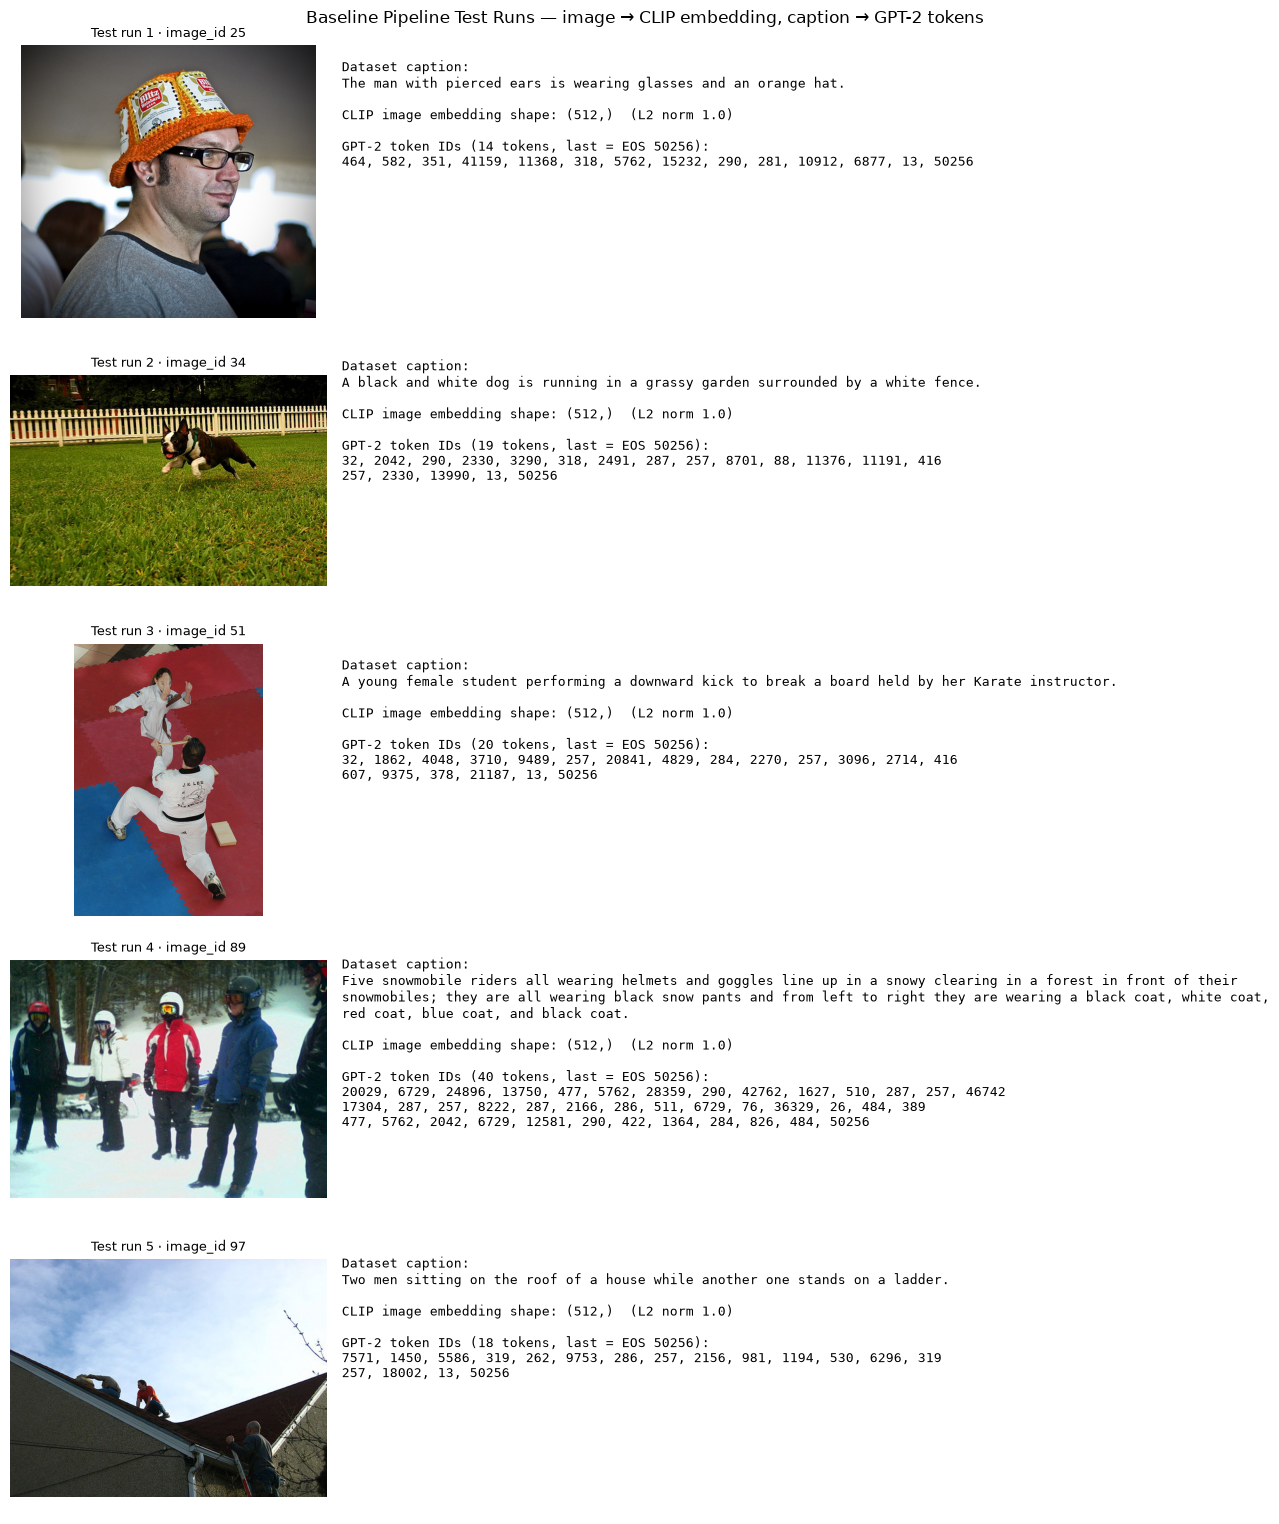

[1] 1007129816.jpg  emb[:8]=[-0.0177, -0.007, 0.0041, 0.0056, -0.0252, -0.004, 0.0077, 0.0255]  norm=1.0
    decoded: 'The man with pierced ears is wearing glasses and an orange hat.<|endoftext|>'
[2] 1009434119.jpg  emb[:8]=[-0.0214, -0.0142, -0.0084, 0.0237, 0.0442, 0.0057, 0.0246, -0.0031]  norm=1.0
    decoded: 'A black and white dog is running in a grassy garden surrounded by a white fence.<|endoftext|>'
[3] 101362133.jpg  emb[:8]=[-0.0009, -0.0058, -0.0019, -0.003, 0.0592, -0.0243, 0.0334, -0.0319]  norm=1.0
    decoded: 'A young female student performing a downward kick to break a board held by her Karate instructor.<|endoftext|>'
[4] 102617084.jpg  emb[:8]=[-0.0426, 0.0211, 0.0084, 0.0238, -0.0451, -0.0113, -0.0144, -0.022]  norm=1.0
    decoded: 'Five snowmobile riders all wearing helmets and goggles line up in a snowy clearing in a forest in front of their snowmobiles; they are all wearing black snow pants and from left to right they<|endoftext|>'
[5] 10287332.jpg  emb[:8]=[0

In [6]:
test_emb = clip_feats["test"]
test_tok = token_feats["test"]
emb_index = {iid: i for i, iid in enumerate(test_emb["image_ids"])}
sample_ids = manifest[manifest.split == "test"].image_id.tolist()[:5]

samples = []
for iid in sample_ids:
    fn = manifest.loc[manifest.image_id == iid, "filename"].item()
    r = next(i for i, x in enumerate(test_tok["image_ids"]) if x == iid)   # first caption of this image
    n = int(test_tok["attention_mask"][r].sum())
    emb = test_emb["embeddings"][emb_index[iid]]
    samples.append({
        "image_id": iid, "filename": fn,
        "caption": captions[(captions.image_id == iid)].caption.iloc[0],
        "embedding_shape": list(emb.shape),
        "embedding_first8": [round(v, 4) for v in emb[:8].tolist()],
        "embedding_norm": round(float(emb.norm()), 4),
        "token_ids": test_tok["input_ids"][r, :n].tolist(),
        "input_ids_padded": test_tok["input_ids"][r].tolist(),
        "attention_mask": test_tok["attention_mask"][r].tolist(),
        "decoded": tokenizer.decode(test_tok["input_ids"][r, :n]),
    })

fig, axes = plt.subplots(len(samples), 2, figsize=(13, 3.1 * len(samples)), gridspec_kw={"width_ratios": [1, 2.6]})
for k, (s, (ax_img, ax_txt)) in enumerate(zip(samples, np.atleast_2d(axes))):
    ax_img.imshow(Image.open(IMG_DIR / s["filename"]).convert("RGB")); ax_img.axis("off")
    ax_img.set_title(f"Test run {k + 1} · image_id {s['image_id']}", fontsize=9)
    ids = s["token_ids"]
    ids_txt = "\n".join(str(ids[i:i + 14])[1:-1] for i in range(0, len(ids), 14))
    ax_txt.axis("off")
    ax_txt.text(0, 0.95, f"Dataset caption:\n{s['caption']}\n\n"
                        f"CLIP image embedding shape: {tuple(s['embedding_shape'])}  (L2 norm {s['embedding_norm']})\n\n"
                        f"GPT-2 token IDs ({len(ids)} tokens, last = EOS {EOS}):\n{ids_txt}",
                va="top", fontsize=9, family="monospace", wrap=True)
fig.suptitle("Baseline Pipeline Test Runs — image → CLIP embedding, caption → GPT-2 tokens", fontsize=12)
plt.tight_layout()
fig.savefig(RESULT_DIR / "baseline_pipeline_test_runs.png", dpi=150, bbox_inches="tight")
plt.show()

with open(RESULT_DIR / "samples.json", "w", encoding="utf-8") as f:
    json.dump(samples, f, indent=2, ensure_ascii=False)

for k, s in enumerate(samples, 1):
    print(f"[{k}] {s['filename']}  emb[:8]={s['embedding_first8']}  norm={s['embedding_norm']}")
    print(f"    decoded: {s['decoded']!r}")

## 7. Optional external demo (off by default)

`RUN_EXTERNAL_DEMO = True` runs an **external pretrained captioner** (`nlpconnect/vit-gpt2-image-captioning`) on the same 5 images. Its captions are **not produced by our pipeline** and are not part of the Milestone 1 results; a failure here never stops the notebook.

In [7]:
if RUN_EXTERNAL_DEMO:
    try:
        from transformers import VisionEncoderDecoderModel, ViTImageProcessor, AutoTokenizer
        name = "nlpconnect/vit-gpt2-image-captioning"
        ext_model = VisionEncoderDecoderModel.from_pretrained(name).to(DEVICE).eval()
        ext_proc, ext_tok = ViTImageProcessor.from_pretrained(name), AutoTokenizer.from_pretrained(name)
        imgs = [Image.open(IMG_DIR / s["filename"]).convert("RGB") for s in samples]
        with torch.no_grad():
            out = ext_model.generate(ext_proc(images=imgs, return_tensors="pt").pixel_values.to(DEVICE), max_length=32, num_beams=4)
        for s, c in zip(samples, ext_tok.batch_decode(out, skip_special_tokens=True)):
            print(f"{s['filename']}\n  dataset caption        : {s['caption']}\n  [external model] caption: {c.strip()}")
    except Exception as e:
        print("external demo skipped:", repr(e))
else:
    print("RUN_EXTERNAL_DEMO = False (skipped)")

RUN_EXTERNAL_DEMO = False (skipped)


## 8. Run summary

In [8]:
run_summary = {
    "mode": "SMOKE_TEST" if SMOKE_TEST else "OFFICIAL",
    "dataset": f"{HF_DATASET}@{HF_REVISION}",
    "images_per_split": manifest.groupby("split").size().to_dict(),
    "pairs_per_split": captions.groupby("split").size().to_dict(),
    "total_pairs": int(n_pairs),
    "clip_model": CLIP_NAME, "embedding_dim": EMB_DIM,
    "tokenizer": GPT2_NAME, "max_len": MAX_LEN,
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "transformers": transformers.__version__, "datasets": datasets.__version__},
    "device": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu",
}
with open(RESULT_DIR / "run_summary.json", "w") as f:
    json.dump(run_summary, f, indent=2)
print(json.dumps(run_summary, indent=2))

{
  "mode": "OFFICIAL",
  "dataset": "nlphuji/flickr30k@refs/convert/parquet",
  "images_per_split": {
    "test": 90,
    "train": 720,
    "val": 90
  },
  "pairs_per_split": {
    "test": 450,
    "train": 3600,
    "val": 450
  },
  "total_pairs": 4500,
  "clip_model": "openai/clip-vit-base-patch32",
  "embedding_dim": 512,
  "tokenizer": "gpt2",
  "max_len": 40,
  "versions": {
    "python": "3.13.7",
    "torch": "2.11.0+cu128",
    "transformers": "5.23.0",
    "datasets": "5.2.0"
  },
  "device": "NVIDIA GeForce RTX 5060"
}
